In [1]:
!wget https://bitbucket.org/ishaanjav/code-and-deploy-custom-tensorflow-lite-model/raw/a4febbfee178324b2083e322cdead7465d6fdf95/fruits.zip

zsh:1: command not found: wget


In [2]:
!unzip fruits.zip

unzip:  cannot find or open fruits.zip, fruits.zip.zip or fruits.zip.ZIP.


In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt

In [4]:
img_height, img_width = 64, 64
batch_size = 20

train_ds = tf.keras.utils.image_dataset_from_directory(
    "fruits/train",
    image_size = (img_height, img_width),
    batch_size = batch_size
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "fruits/validation",
    image_size = (img_height, img_width),
    batch_size = batch_size
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "fruits/test",
    image_size = (img_height, img_width),
    batch_size = batch_size
)

FileNotFoundError: [Errno 2] No such file or directory: 'fruits/train'

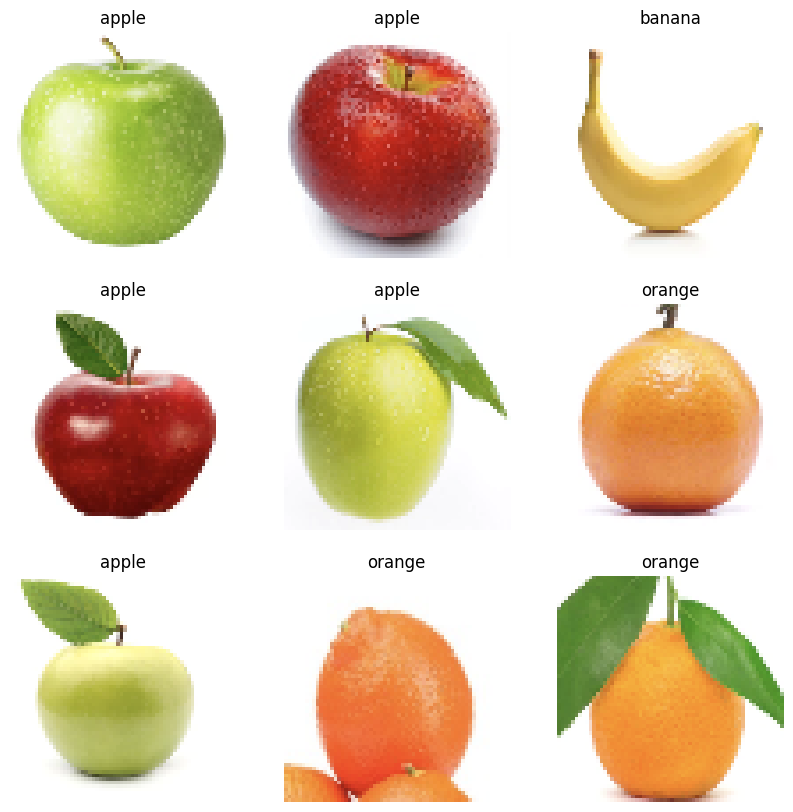

In [ ]:
class_names = ["apple", "banana", "orange"]
plt.figure(figsize=(10,10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [ ]:
model = tf.keras.Sequential(
    [
     tf.keras.layers.Rescaling(1./255),
     tf.keras.layers.Conv2D(32, 3, activation="relu"),
     tf.keras.layers.MaxPooling2D(),
     tf.keras.layers.Conv2D(32, 3, activation="relu"),
     tf.keras.layers.MaxPooling2D(),
     tf.keras.layers.Conv2D(32, 3, activation="relu"),
     tf.keras.layers.MaxPooling2D(),
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation="relu"),
     tf.keras.layers.Dense(3)
    ]
)


In [ ]:
model.compile(
    optimizer="adam",
    loss=tf.losses.SparseCategoricalCrossentropy(from_logits = True),
    metrics=['accuracy']
)

In [ ]:
model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 10
)

Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.6370 - loss: 0.8438 - val_accuracy: 0.7576 - val_loss: 0.5734
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8783 - loss: 0.3229 - val_accuracy: 0.8333 - val_loss: 0.5296
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8761 - loss: 0.3277 - val_accuracy: 0.8788 - val_loss: 0.3528
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9478 - loss: 0.1504 - val_accuracy: 0.9242 - val_loss: 0.2583
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9413 - loss: 0.1361 - val_accuracy: 0.9394 - val_loss: 0.1376
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9587 - loss: 0.1201 - val_accuracy: 0.9697 - val_loss: 0.1214
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9696 - loss: 0.0898 - val_accuracy: 0.9242 - val_loss: 0.1871
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9739 - loss: 0.0678 - val_accuracy: 0.9848 - v

In [ ]:
model.evaluate(test_ds)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9538 - loss: 0.1256


[0.1255628615617752, 0.9538461565971375]

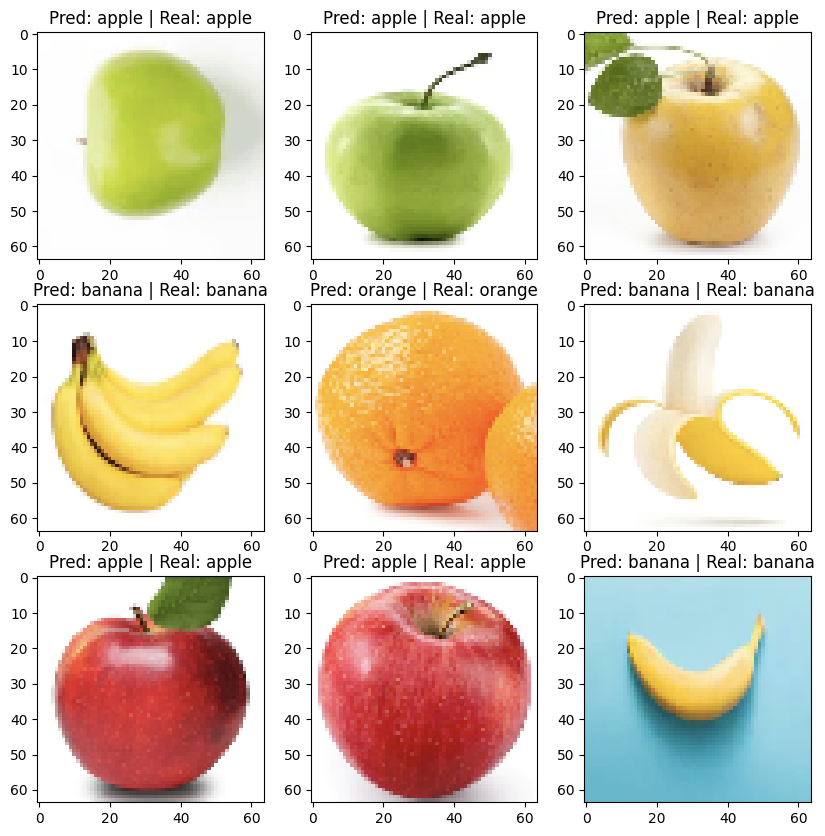

In [ ]:
import numpy

plt.figure(figsize=(10,10))
for images, labels in test_ds.take(1):
  classifications = model(images)
  # print(classifications)

  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    index = numpy.argmax(classifications[i])
    plt.title("Pred: " + class_names[index] + " | Real: " + class_names[labels[i]])

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open("fruits_model.tflite", 'wb') as f:
  f.write(tflite_model)

INFO:tensorflow:Assets written to: C:\Users\pc\AppData\Local\Temp\tmpfj7px9vk\assets


INFO:tensorflow:Assets written to: C:\Users\pc\AppData\Local\Temp\tmpfj7px9vk\assets


Saved artifact at 'C:\Users\pc\AppData\Local\Temp\tmpfj7px9vk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2624354357456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354358992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354359184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354359568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354358416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354359952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354358224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354360912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354360336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2624354361872: TensorSpec(shape=(), dtype=tf.resource, name=None)
